<a href="https://colab.research.google.com/github/dinarrahman30/ml_midexam/blob/main/20926006_SK5017_MidExam_Part_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 3: Clustering

In [1]:
!pip install ucimlrepo

import pandas as pd
from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# fetch dataset
abalone = fetch_ucirepo(id=1)

# Extract features and target dataframes
X = abalone.data.features

{'uci_id': 1, 'name': 'Abalone', 'repository_url': 'https://archive.ics.uci.edu/dataset/1/abalone', 'data_url': 'https://archive.ics.uci.edu/static/public/1/data.csv', 'abstract': 'Predict the age of abalone from physical measurements', 'area': 'Biology', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Tabular'], 'num_instances': 4177, 'num_features': 8, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': [], 'target_col': ['Rings'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1994, 'last_updated': 'Mon Aug 28 2023', 'dataset_doi': '10.24432/C55C7W', 'creators': ['Warwick Nash', 'Tracy Sellers', 'Simon Talbot', 'Andrew Cawthorn', 'Wes Ford'], 'intro_paper': None, 'additional_info': {'summary': 'Predicting the age of abalone from physical measurements.  The age of abalone is determined by cutting the shell through the cone, staining it, and counting the number of rings through a microscope -- 

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, SpectralClustering, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from scipy.cluster.hierarchy import dendrogram, linkage

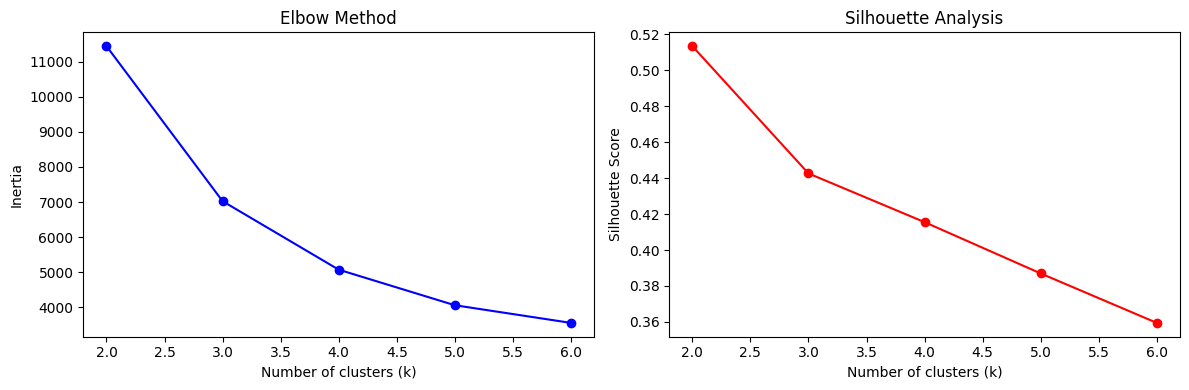

Selected Optimal Number of Clusters: 3



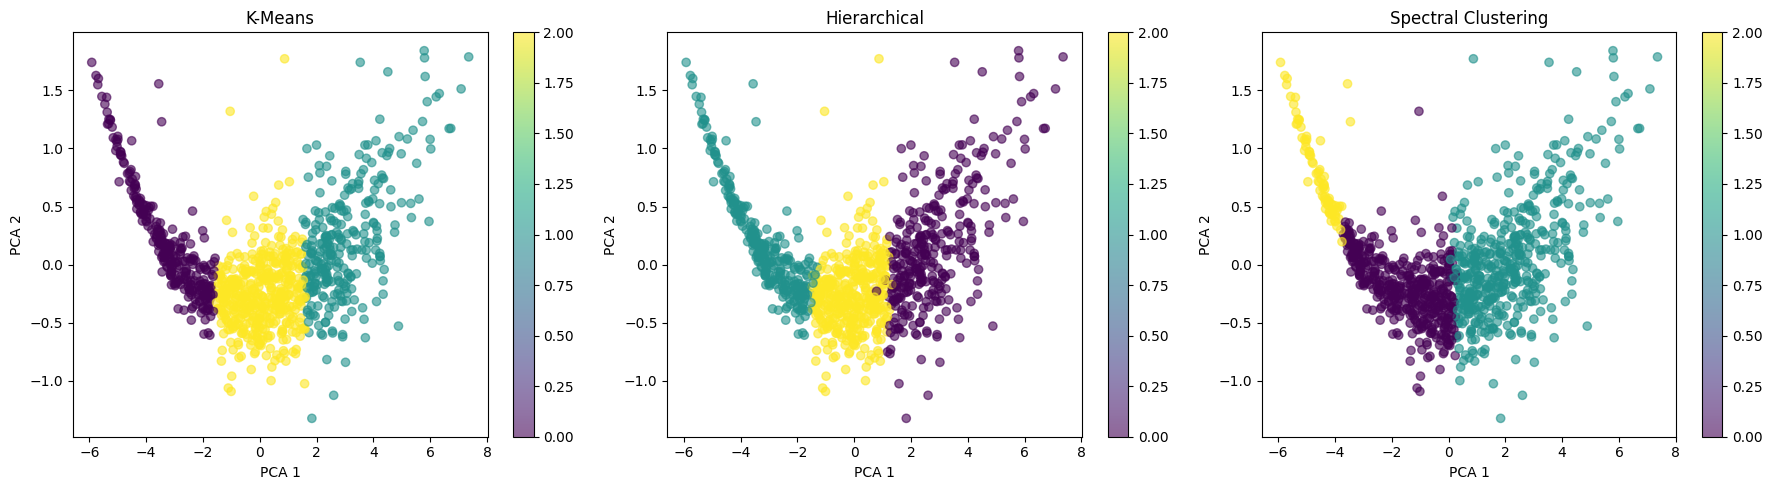

--- K-Means Alignment --- 
Alignment with Sex  -> ARI: 0.1492 | NMI: 0.1894
Alignment with Rings -> ARI: 0.0740 | NMI: 0.1787

--- Hierarchical Alignment --- 
Alignment with Sex  -> ARI: 0.1622 | NMI: 0.1885
Alignment with Rings -> ARI: 0.0781 | NMI: 0.1830

--- Spectral Clustering Alignment --- 
Alignment with Sex  -> ARI: 0.1586 | NMI: 0.1861
Alignment with Rings -> ARI: 0.0661 | NMI: 0.1832



In [5]:
# 1. Isolate and Scale Continuous Physical Features
X_continuous = X.drop(columns=['Sex'])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_continuous)

# 2. Determine Optimal Number of Clusters (Elbow and Silhouette)
inertias = []
silhouette_scores = []
K_range = range(2, 7)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

# Plotting Elbow and Silhouette
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(K_range, inertias, 'bo-')
ax1.set_xlabel('Number of clusters (k)')
ax1.set_ylabel('Inertia')
ax1.set_title('Elbow Method')

ax2.plot(K_range, silhouette_scores, 'ro-')
ax2.set_xlabel('Number of clusters (k)')
ax2.set_ylabel('Silhouette Score')
ax2.set_title('Silhouette Analysis')
plt.tight_layout()
plt.show()

# We will use k=3 because it is highly interpretable (e.g., matching the 3 sexes: M, F, I)
optimal_k = 3
print(f"Selected Optimal Number of Clusters: {optimal_k}\n")

# To ensure fast execution of Spectral Clustering, we use a stratified subsample
np.random.seed(42)
sample_indices = np.random.choice(len(X_scaled), size=1000, replace=False)
X_sub = X_scaled[sample_indices]
target_sex_sub = X['Sex'].iloc[sample_indices]
target_rings_sub = y['Rings'].iloc[sample_indices]

# 3. Implement the 3 Clustering Algorithms
# K-means
km = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
km_labels = km.fit_predict(X_sub)

# Hierarchical Clustering (Ward linkage)
hc = AgglomerativeClustering(n_clusters=optimal_k, linkage='ward')
hc_labels = hc.fit_predict(X_sub)

# Spectral Clustering
sc = SpectralClustering(n_clusters=optimal_k, random_state=42, affinity='nearest_neighbors', n_init=10)
sc_labels = sc.fit_predict(X_sub)

# 4. Visualization using 2D PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_sub)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
algos = [('K-Means', km_labels), ('Hierarchical', hc_labels), ('Spectral Clustering', sc_labels)]

for ax, (title, labels) in zip(axes, algos):
    scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='viridis', alpha=0.6)
    ax.set_title(title)
    ax.set_xlabel('PCA 1')
    ax.set_ylabel('PCA 2')
    fig.colorbar(scatter, ax=ax)
plt.tight_layout()
plt.show()

# 5. Evaluate Alignment with Target Variables (Sex & Age/Rings)
for title, labels in algos:
    print(f"--- {title} Alignment --- ")
    # Alignment with Sex
    ari_sex = adjusted_rand_score(target_sex_sub, labels)
    nmi_sex = normalized_mutual_info_score(target_sex_sub, labels)
    print(f"Alignment with Sex  -> ARI: {ari_sex:.4f} | NMI: {nmi_sex:.4f}")

    # Alignment with Rings (Age)
    ari_rings = adjusted_rand_score(target_rings_sub, labels)
    nmi_rings = normalized_mutual_info_score(target_rings_sub, labels)
    print(f"Alignment with Rings -> ARI: {ari_rings:.4f} | NMI: {nmi_rings:.4f}\n")

# Comparison and Suitability Discussion
--- DISCUSSION & COMPARISON ---
1. Alignment with Target Variables:
   - Both ARI and NMI scores show relatively weak alignment with 'Sex' and 'Rings' (Age).
   - This is because physical characteristics of abalones overlap heavily across sexes (males and females are structurally identical, while infants overlap heavily with younger adults).
   - Rings represent a continuous timeline rather than discrete physical boundaries, making strict cluster partitioning align poorly with individual ages.

2. Algorithm Suitability for This Data:
   - K-means: Extremely fast and appropriate if we expect convex, spherical cluster shapes. However, physical sizes of abalones are highly correlated (forming an elongated/ellipsoidal continuous manifold), violating strict spherical assumptions.
   - Hierarchical Clustering: Valuable for interpreting relationships and biological taxonomies through dendrograms, but less scalable to large datasets.
   - Spectral Clustering: Can capture non-convex boundaries and complex manifolds. Given the continuous, highly-correlated, and non-linear physical growth patterns of the abalone dataset, Spectral Clustering is theoretically more suited to capture the continuous structural transition of abalones as they grow.
